In [1]:
import polars as pl
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import altair as alt

import itables
import itables.options as opt

import statsmodels.api as sm

In [2]:
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [3]:
itables.init_notebook_mode(all_interactive=True)
opt.maxBytes = 0          # no byte limit (default is ~64KB)
opt.maxRows = 0           # no row limit
opt.maxColumns = 0        # no column limit

In [4]:
df = pl.read_parquet("1d_candle_panel_cleaned_universe.parquet")

# Compute 30 day median daily dollar volume

In [5]:
df = df.with_columns(
    (pl.col("volume") * pl.col("close")).alias("dollar_volume")
)

In [6]:
df = df.with_columns(
    pl.col("dollar_volume")
    .rolling_median_by("timestamp", "30d", min_samples=30)
    .over("symbol")
    .alias("30_mdv")
)

In [7]:
df = df.with_columns(
    pl.col("30_mdv").shift(1).over("symbol").alias("30_mdv_lag")
)

In [8]:
df = df.drop_nans().drop_nulls()
df = df.filter(pl.col("timestamp") >= pl.datetime(2024, 1, 1, time_zone="UTC"))
# require enough names for 3 bins at 30/70 (>= ~10 gives >=2 per tail bin)

# Label symbols by 30 day median daily volume quantile by date

In [9]:
df = df.with_columns(
    pl.col("30_mdv_lag")
    .bin_quantiles([0.1, 0.9], labels=["low", "mid", "high"])
    .over("timestamp")
    .alias("quantile")
)

In [10]:
df.group_by("symbol").agg(pl.col("30_mdv").mean())

shape: (152, 2)
┌─────────┬──────────┐
│ symbol  ┆ 30_mdv   │
│ ---     ┆ ---      │
│ str     ┆ f64      │
╞═════════╪══════════╡
│ USUAL   ┆ 1.9778e6 │
│ PURR    ┆ 2.6359e6 │
│ kSHIB   ┆ 3.2790e6 │
│ STRK    ┆ 3.2100e6 │
│ BIGTIME ┆ 1.1682e6 │
│ …       ┆ …        │
│ HYPER   ┆ 1.1543e6 │
│ FET     ┆ 2.6628e6 │
│ PONS    ┆ 7.5089e6 │
│ ASTER   ┆ 1.0162e7 │
│ GALA    ┆ 1.6436e6 │
└─────────┴──────────┘

# Create long panel dataframe of equal weighted (daily rebalanced) indexes for each liquidity quantile

In [11]:
indexes = df.group_by(["timestamp", "quantile"]).agg(
    pl.col("log_return").exp().mean().log().alias("log_return")
).sort(["quantile", "timestamp"])

In [12]:
indexes.group_by("quantile").agg(pl.col("timestamp").min())

shape: (3, 2)
┌──────────┬─────────────────────────┐
│ quantile ┆ timestamp               │
│ ---      ┆ ---                     │
│ enum     ┆ datetime[μs, UTC]       │
╞══════════╪═════════════════════════╡
│ low      ┆ 2024-01-06 00:00:00 UTC │
│ mid      ┆ 2024-01-01 00:00:00 UTC │
│ high     ┆ 2024-01-01 00:00:00 UTC │
└──────────┴─────────────────────────┘

In [13]:
# Make all quintiles have the same starting timestamp

indexes = indexes.filter(
    pl.col("timestamp") >= pl.col("timestamp").min().over("quantile").max()
)

In [14]:
indexes = indexes.with_columns(
    pl.col("log_return").cum_sum().exp().over("quantile").alias("close")
)

In [15]:
indexes

shape: (3_111, 4)
┌─────────────────────────┬──────────┬────────────┬──────────┐
│ timestamp               ┆ quantile ┆ log_return ┆ close    │
│ ---                     ┆ ---      ┆ ---        ┆ ---      │
│ datetime[μs, UTC]       ┆ enum     ┆ f64        ┆ f64      │
╞═════════════════════════╪══════════╪════════════╪══════════╡
│ 2024-01-06 00:00:00 UTC ┆ low      ┆ -0.031722  ┆ 0.968775 │
│ 2024-01-07 00:00:00 UTC ┆ low      ┆ -0.059888  ┆ 0.91246  │
│ 2024-01-08 00:00:00 UTC ┆ low      ┆ -0.079434  ┆ 0.842784 │
│ 2024-01-09 00:00:00 UTC ┆ low      ┆ 0.078418   ┆ 0.911534 │
│ 2024-01-10 00:00:00 UTC ┆ low      ┆ -0.035698  ┆ 0.879568 │
│ …                       ┆ …        ┆ …          ┆ …        │
│ 2026-11-03 00:00:00 UTC ┆ high     ┆ -0.048509  ┆ 1.44041  │
│ 2026-11-04 00:00:00 UTC ┆ high     ┆ 0.027675   ┆ 1.48083  │
│ 2026-11-05 00:00:00 UTC ┆ high     ┆ 0.029513   ┆ 1.525185 │
│ 2026-11-06 00:00:00 UTC ┆ high     ┆ -0.06959   ┆ 1.422655 │
│ 2026-11-07 00:00:00 UTC ┆ high     ┆ 0.012544   ┆ 1.440613 │
└─────────────────────────┴──────────┴────────────┴──────────┘

# Plot time series of all indexes

In [16]:
chart = (
    alt.Chart(indexes.sort("timestamp"))
    .mark_line(strokeWidth=1)
    .encode(
        x="timestamp:T",
        y=alt.Y("close:Q", scale=alt.Scale(zero=False)),
        color=alt.Color("quantile:N", sort=["low", "mid", "high"]),
        tooltip=["timestamp:T", "quantile:N", "close:Q"],
    )
    .properties(width=900, height=400)
    .interactive()
)
chart

alt.Chart(...)

# Compute volatility for all indexes

In [17]:
indexes = indexes.sort(["quantile", "timestamp"]).with_columns(
    pl.col("log_return").pow(2).ewm_mean(span=36, adjust=False, min_samples=36).sqrt().shift(1).over("quantile")
    .alias("vol")
).sort(["quantile", "timestamp"]).drop_nans().drop_nulls()

# Compute vol normalised log_returns for all indexes (annual target vol = 20%)

In [18]:
k = (0.20 / np.sqrt(365)) / pl.col("vol")

indexes = indexes.with_columns(
    (1 + k * (pl.col("log_return").exp() - 1)).log().alias("vn_log_return")
)

In [19]:
len(indexes.filter(pl.col("quantile") == "low"))

1001

In [20]:
len(indexes.filter(pl.col("quantile") == "high"))

1001

# Compute spreads

In [21]:
indexes_wide = (
    indexes.pivot(on="quantile", index="timestamp", values="vn_log_return")
    .rename({
        "low": "low_vn_log_return",
        "mid": "mid_vn_log_return",
        "high": "high_vn_log_return",
    })
    .select(["timestamp", "low_vn_log_return", "mid_vn_log_return", "high_vn_log_return"])
    .sort("timestamp")
)

missing = indexes_wide.select(
    pl.any_horizontal(pl.all().exclude("timestamp").is_null()).sum()
).item()
print(f"dates missing at least one bucket: {missing}")

dates missing at least one bucket: 0


In [22]:
indexes_wide

shape: (1_001, 4)
┌─────────────────────────┬───────────────────┬───────────────────┬────────────────────┐
│ timestamp               ┆ low_vn_log_return ┆ mid_vn_log_return ┆ high_vn_log_return │
│ ---                     ┆ ---               ┆ ---               ┆ ---                │
│ datetime[μs, UTC]       ┆ f64               ┆ f64               ┆ f64                │
╞═════════════════════════╪═══════════════════╪═══════════════════╪════════════════════╡
│ 2024-02-11 00:00:00 UTC ┆ 0.002223          ┆ 0.00139           ┆ 0.004281           │
│ 2024-02-12 00:00:00 UTC ┆ 0.002604          ┆ 0.00008           ┆ -0.002566          │
│ 2024-02-13 00:00:00 UTC ┆ 0.011067          ┆ 0.019456          ┆ 0.015207           │
│ 2024-02-14 00:00:00 UTC ┆ -0.000814         ┆ 0.000575          ┆ 0.001059           │
│ 2024-02-15 00:00:00 UTC ┆ 0.005234          ┆ 0.023098          ┆ 0.013333           │
│ …                       ┆ …                 ┆ …                 ┆ …                  │
│ 2026-11-03 00:00:00 UTC ┆ -0.008651         ┆ -0.010815         ┆ -0.017336          │
│ 2026-11-04 00:00:00 UTC ┆ 0.001604          ┆ 0.004192          ┆ 0.009669           │
│ 2026-11-05 00:00:00 UTC ┆ 0.010604          ┆ 0.006709          ┆ 0.010363           │
│ 2026-11-06 00:00:00 UTC ┆ -0.024306         ┆ -0.024294         ┆ -0.023682          │
│ 2026-11-07 00:00:00 UTC ┆ 0.003171          ┆ 0.005878          ┆ 0.003946           │
└─────────────────────────┴───────────────────┴───────────────────┴────────────────────┘

In [23]:
indexes_wide = indexes_wide.with_columns(
    (pl.col("high_vn_log_return") - pl.col("low_vn_log_return")).alias("HML_log_return"),
    (pl.col("high_vn_log_return") - pl.col("mid_vn_log_return")).alias("HMM_log_return"),
    (pl.col("mid_vn_log_return") - pl.col("low_vn_log_return")).alias("MML_log_return"),
)

# High Minus Low spread

<Axes: title={'center': 'HML'}>

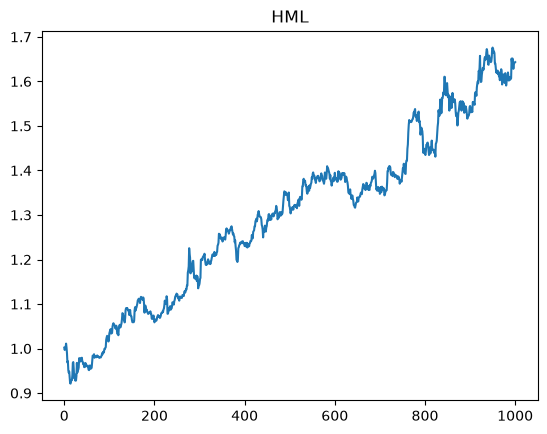

In [24]:
indexes_wide.to_pandas()["HML_log_return"].cumsum().apply(np.exp).plot(title="HML")

In [25]:
print(f"HML Sharpe = {indexes_wide["HML_log_return"].mean() / indexes_wide["HML_log_return"].std() * np.sqrt(365)}")

HML Sharpe = 1.3569492273837176


# High Minus Mid spread

<Axes: title={'center': 'HMM'}>

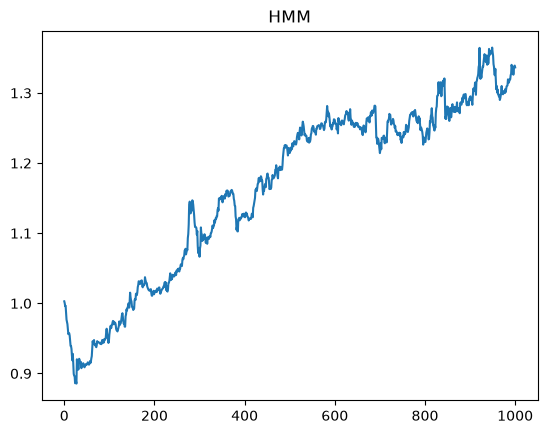

In [26]:
indexes_wide.to_pandas()["HMM_log_return"].cumsum().apply(np.exp).plot(title="HMM")

In [27]:
print(f"HMM Sharpe = {indexes_wide["HMM_log_return"].mean() / indexes_wide["HMM_log_return"].std() * np.sqrt(365)}")

HMM Sharpe = 1.0690714671958963


# Mid Minus Low spread

<Axes: title={'center': 'MML'}>

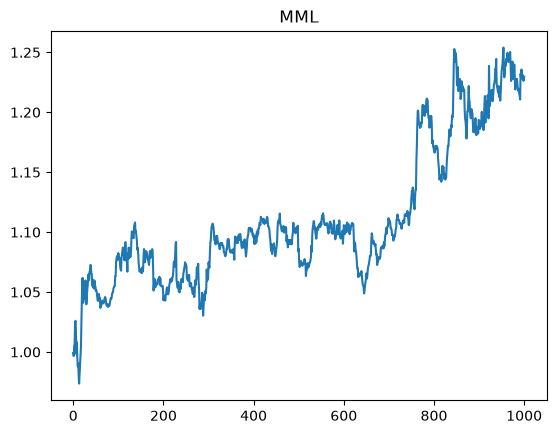

In [28]:
indexes_wide.to_pandas()["MML_log_return"].cumsum().apply(np.exp).plot(title="MML")

In [29]:
print(f"MML Sharpe = {indexes_wide["MML_log_return"].mean() / indexes_wide["MML_log_return"].std() * np.sqrt(365)}")

MML Sharpe = 0.7491687444583996


# Correlation between High - Low, High - Mid, Mid - Low spreads

<Axes: >

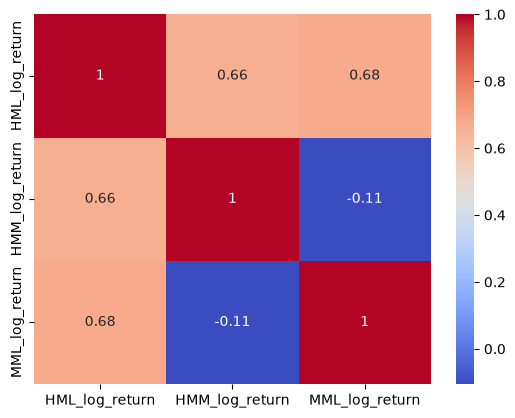

In [30]:
sns.heatmap(
    data=indexes_wide[["HML_log_return", "HMM_log_return", "MML_log_return"]].to_pandas().corr(),
    cmap="coolwarm",
    annot=True
)